# Descriptives

## TOC 

- [Setup & Git](#setup)
- [Load and Preprocess Kern et al. & GPT Tweets](#load_preprocess_tweets)
- [Model Confidence based on Empirical Shannon Entropy](#certainty_1)
- [Model Confidence based of self-reports by the model](#certainty_2)
- [Model Confidence based on LogProb Assessment](#certainty_3)

# Stuff to Check For / Analysis Ideas
- compare prevalences with those from Kern et al Paper 
- calculate agreement per tweets across the different conditions
- order effects (compare batch prompted with single-tweet prompted tweets)
- compare uncertainty measures per conditions (empirical entropy, confidence scores, etc.)

<a id="setup"></a>
## Setup & Git

In [2]:
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import os 
import pandas as pd
import re

<a id="load_preprocess_tweets"></a>
## Load and Preprocess the GPT Labelled Tweets

### Load and rbind the GPT Labeled Tweets

In [3]:
# # load the ZERO-SHOT annotations 
# DATE_TO_IMPORT = '2025_04_10'

# files = os.listdir('Data_Collection/')
# files_to_select = list(filter(lambda filename: filename.startswith(DATE_TO_IMPORT), files))
# files_to_select = [f"Data_Collection/{filename}" for filename in files_to_select]

# # read and concat files 
# dataframes = [pd.read_csv(file) for file in files_to_select]
# combined_df_z = pd.concat(dataframes, sort=False, ignore_index=True)
# combined_df_z.sort_values(['batch_id', 'tweet_in_batch'], inplace=True)


# load the FEW-SHOT annotations 
DATE_TO_IMPORT = '2025_07_01'

files = os.listdir('Data_Collection/OL_NH')
files_to_select = list(filter(lambda filename: filename.startswith(DATE_TO_IMPORT), files))
files_to_select = [f"Data_Collection/OL_NH/{filename}" for filename in files_to_select]

# read and concat files 
dataframes = [pd.read_csv(file) for file in files_to_select]
combined_df_f = pd.concat(dataframes, sort=False, ignore_index=True)
combined_df_f.sort_values(['batch_id', 'tweet_in_batch'], inplace=True)

# Concat the tweets and add zero- vs. few-shot column
# combined_df_z.insert(5,'shot','zero-shot')
combined_df_f.insert(5,'shot','few-shot')
combined_df = combined_df_f


# Sekect combined df subset 
combined_df = combined_df[combined_df['shot'] == 'few-shot']


n_tweets = len(combined_df['tweet'].drop_duplicates())
n_tweet_batches = len(combined_df['batch_id'].drop_duplicates())
n_conditions = len(combined_df['condition'].drop_duplicates())
# conditions = combined_df['condition'].drop_duplicates()


print(f'Unique Tweets: {n_tweets}')
print(f'No. Batches: {n_tweet_batches}')
# print(f'Conditions: {n_conditions} --> {conditions}')

combined_df[combined_df['tweet_id'] == 1371].head(2)

Unique Tweets: 2998
No. Batches: 500


,batch_id,tweet_in_batch,tweet_id,tweet,condition,shot,R1_response,R2_response,R3_response,R1_label,...,R2_Token1,R2_Token2,R2_Token3,R2_Token4,R2_Token5,R3_Token1,R3_Token2,R3_Token3,R3_Token4,R3_Token5
16,1,5,1371,@###### I'm the type to put that bitch in a ri...,A_conf,few-shot,"OL90, NH85","OL90, NH95","OL90, NH95","['OL', 'NH']",...,OL 0.000 \n OL -17.250\nAL -18.625\nU...,90 -0.119470\n95 -2.994470\n100 -3.369...,", 0.000 \n; -24.000\n , -24.500\n， ...",NH -1.936126e-07\n NO -1.625000e+01\n HS ...,95 -0.586762\n85 -0.836762\n100 -5.586...,OL 0.000 \n OL -17.250\nAL -18.625\nU...,90 -0.119174\n95 -2.994174\n100 -3.494...,", 0.000 \n; -23.375\n , -24.000\n， ...",NH -7.896310e-07\n NO -1.425000e+01\n HS ...,95 -0.482695\n85 -0.982695\n80 -5.857...
17,1,5,1371,@###### I'm the type to put that bitch in a ri...,B_conf,few-shot,"NH80, OL90","NH90, OL95","NH70, OL90","['NH', 'OL']",...,NH -0.000124 \nHS -9.000124 \n NH -15....,70 -0.507592\n90 -2.007592\n80 -2.257592...,", 0.000 \n; -24.125\n , -25.000\n， ...",OL 0.000 \nOL -19.250\n -24.125\n ...,85 -1.2039\n95 -1.3289\n90 -1.5789\n1...,NH -0.000002 \nHS -13.250002\n NH -14....,70 -1.133885\n90 -1.258885\n85 -1.633885...,", 0.00 \n , -24.00\n; -24.50\n， -2...",OL 0.00 \nOL -19.50\n -23.25\n UL ...,90 -0.008996\n85 -5.133996\n95 -6.008...


### Preprocess GPT Labels
- Get to long format 
- Quality Checks (Compliance)
- Create binary OL and HS indicator columns

In [4]:
# Get from Wide Format to Proper Long Format
### List of columns that are shared among all tweets
shared_cols = ['batch_id', 'tweet_in_batch', 'tweet_id', 'tweet', 
               'condition', 'shot']

### List to hold the DataFrame for each responder
df_list = []

# Loop over each responder identifier (R1, R2, R3)
for responder in ['R1', 'R2', 'R3']:
    # Create a new DataFrame from old columns and responder col
    df_temp = combined_df[shared_cols].copy()
    df_temp['responder'] = responder

    # Add the responder-specific columns by using the respective column names
    df_temp['label'] = combined_df[f'{responder}_label']
    df_temp['score'] = combined_df[f'{responder}_score']
    df_temp['Token1'] = combined_df[f'{responder}_Token1']
    df_temp['Token2'] = combined_df[f'{responder}_Token2']
    df_temp['Token3'] = combined_df[f'{responder}_Token3']

    # Append the new DataFrame to the list
    df_list.append(df_temp)

# Concatenate all responder DataFrames into one
df_long = pd.concat(df_list, ignore_index=True)

# create OL / HS Indicator Columns
df_long['OL'] = np.where(df_long['label'].str.contains(r'(?<!N)OL'), 1, 0) # match OL but not NOL
df_long['HS'] = np.where(df_long['label'].str.contains(r'(?<!N)HS'), 1, 0) # same

# check NA counts for confidence scores per condition
# df_long.groupby('condition')['score'].apply(lambda x: x.isna().sum())
df_long[df_long['condition'] == 'B_conf'].iloc[50:52,]

,batch_id,tweet_in_batch,tweet_id,tweet,condition,shot,responder,label,score,Token1,Token2,Token3,OL,HS
801,9,3,1446,@###### @###### he wasn't training gook boy doe,B_conf,few-shot,R1,"['HS', 'OL']","['95', '90']",HS 0.000 \n HS -16.750\nNH -17.625\nH...,90 -0.59346\n95 -0.84346\n100 -4.21846...,", 0.000 \n , -23.875\n; -24.250\n، ...",1,1
817,9,4,2739,I miss my monkey &#128533;,B_conf,few-shot,R1,"['NH', 'NO']","['90', '100']",NH -3.128163e-07\n NH -1.550000e+01\nNh ...,90 -0.083106\n95 -2.583106\n85 -5.708...,", 0.000 \n; -23.625\n , -24.250\n， ...",0,0


<a id="certainty_1"></a>
## Approach 1 to certainty assessment (all conditions) - Binary Shannon Entropy

i.e., Group by Tweet and Condition and Calculate the Empirical Entropy / SD for each combination of tweet x condition
e.g.   
tweet A in condition X: OL-Ratings: 1, 0, 1 --> Entropy =  ~1 bit  
tweet B in condition X: OL-Ratings: 1, 1, 1 --> Entropy =   0 bit  

--> This approach should be affected by the temperature choice (we used 1)  
as temperature directly influences which tokens get selected (and thus the response)  
This, however, is not the case for the log prob probabilities

In [5]:
# Create DF for entropy calculation 
# --> i.e., merge the C.OL and C.HS conditions to one condition
# base df
entropy_df = combined_df[['batch_id', 'tweet_in_batch', 'tweet_id',  'tweet', 
                          'condition', 'shot', 
                          'R1_label', 'R2_label', 'R3_label']].copy()

key_cols = ["batch_id", "tweet_in_batch", "tweet_id", 
            "tweet", "condition", "shot",
            "R1_label", "R2_label", "R3_label", 
            "cond_clean"]

# extract binary OL and HS labels for every row 
entropy_df['R1_OL'] = np.where(entropy_df['R1_label'].str.contains(r'(?<!N)OL'), 1, 0)
entropy_df['R2_OL'] = np.where(entropy_df['R2_label'].str.contains(r'(?<!N)OL'), 1, 0)
entropy_df['R3_OL'] = np.where(entropy_df['R3_label'].str.contains(r'(?<!N)OL'), 1, 0)

entropy_df['R1_HS'] = np.where(entropy_df['R1_label'].str.contains(r'(?<!N)HS'), 1, 0)
entropy_df['R2_HS'] = np.where(entropy_df['R2_label'].str.contains(r'(?<!N)HS'), 1, 0)
entropy_df['R3_HS'] = np.where(entropy_df['R3_label'].str.contains(r'(?<!N)HS'), 1, 0)


# create additional C. col for C.HS and C.OL cases
entropy_df['cond_clean'] = entropy_df['condition'].str.replace(r'\.OL|\.HS', '', regex=True)


# A & B conditions --> nothing special to do --> join binary ratings
entropy_df_A_B = entropy_df[entropy_df['condition']
                            .str.contains(r'[AB]', na=False)].copy()[key_cols]
entropy_df_A_B = entropy_df_A_B.merge(entropy_df[['tweet', 'cond_clean', 
                                                  'R1_OL', 'R2_OL', 'R3_OL',
                                                  'R1_HS', 'R2_HS', 'R3_HS']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])

# C conditions --> sepcial: join binary OL ratings from C.OL base df 
#                           same for binary HS ratings

entropy_df_C = entropy_df[key_cols].copy().drop_duplicates(subset=['tweet_id', 'cond_clean'])

# join binary OL ratings
entropy_df_C = entropy_df_C.merge(entropy_df[entropy_df['condition'].str.contains(r'C\.OL', na=False)]
                                  [['tweet', 'cond_clean', 'R1_OL', 'R2_OL', 'R3_OL']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])
# join binary HS ratings
entropy_df_C = entropy_df_C.merge(entropy_df[entropy_df['condition'].str.contains(r'C\.HS', na=False)]
                                  [['tweet', 'cond_clean', 'R1_HS', 'R2_HS', 'R3_HS']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])


# Concat to get the final reformatted df for calculating entropies
entropy_df = pd.concat([entropy_df_A_B, entropy_df_C], 
                       ignore_index=True, sort=False)


# Checks: --> the number of C rows should have halved --> WORKS 
print(entropy_df_A_B.shape)
print(entropy_df_C.shape)
print(entropy_df.shape)
entropy_df[entropy_df['cond_clean'] == 'C'].head()

(23067, 16)
(11561, 16)
(34628, 16)


,batch_id,tweet_in_batch,tweet_id,tweet,condition,shot,R1_label,R2_label,R3_label,cond_clean,R1_OL,R2_OL,R3_OL,R1_HS,R2_HS,R3_HS
23068,1,1,811,Fat fucking funky nasty ass hoes,C.HS,few-shot,HS,HS,HS,C,1,1,1,1,1,1
23072,1,2,742,Up early then a bitch driving to denton omg ca...,C.HS,few-shot,NH,NH,NH,C,1,1,1,0,0,0
23076,1,3,2098,@###### @###### there isn't a green one either...,C.HS,few-shot,NH,NH,NH,C,0,0,0,0,0,0
23080,1,4,2349,The only thing about niccas is they be followe...,C.HS,few-shot,HS,HS,HS,C,1,1,1,1,1,1
23084,1,5,1371,@###### I'm the type to put that bitch in a ri...,C.HS,few-shot,NH,NH,NH,C,1,1,1,0,0,0


In [6]:
# Calculate Entropy Values
# Calculate Entropies per Tweet X Condition in 2 extra cols
def binary_entropy(p):
    """ Calculcate Binary Shannon Entropy
    H(p) = -p log2 p - (1-p) log2(1-p), with H(0)=H(1)=0"""
    return -(
        np.where(p > 0,   p * np.log2(p),   0) +
        np.where(p < 1, (1 - p) * np.log2(1 - p), 0)
    )

p_ol = entropy_df[['R1_OL', 'R2_OL', 'R3_OL']].mean(axis=1)
p_hs = entropy_df[['R1_HS', 'R2_HS', 'R3_HS']].mean(axis=1)

entropy_df['entropy_OL'] = binary_entropy(p_ol)
entropy_df['entropy_HS'] = binary_entropy(p_hs)
entropy_df.head(30)

# Calculate Entropies per Tweet X Condition in 2 extra cols
# of course function of temperature 
# but can also be considered a function of uncertainty 
# proportional to the factor of temperature

# Calculcate Mean Entropies per condition and Outcome (HS/OL)
mean_entropy_wide = (
    entropy_df.groupby('cond_clean', as_index=False)
      .agg(mean_entropy_OL = ('entropy_OL', 'mean'),
           mean_entropy_HS = ('entropy_HS', 'mean'))
)
# mean_entropy_wide

/Users/thomasreiter/anaconda3/lib/python3.11/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/thomasreiter/anaconda3/lib/python3.11/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


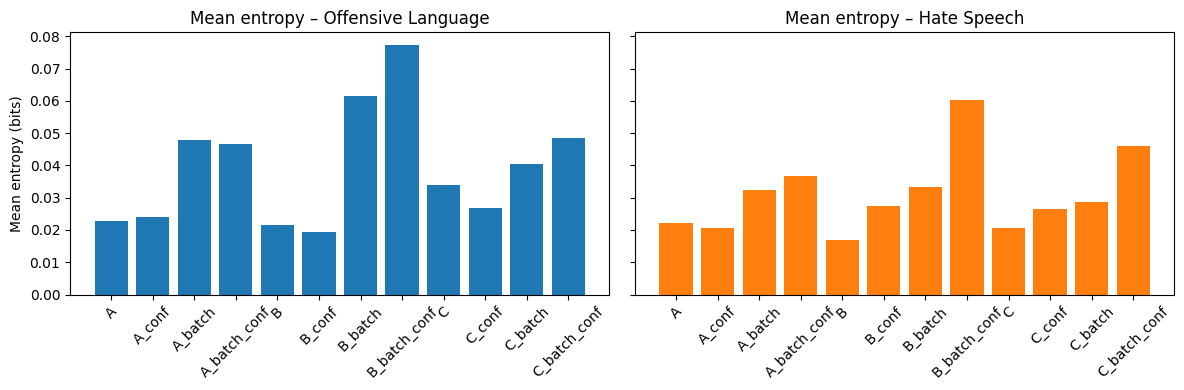

In [7]:
# Visualize Entropy
import pandas as pd
import matplotlib.pyplot as plt

# palette and ordering
palette = {'OL': '#1f77b4', 'HS': '#ff7f0e'}
condition_order = [
    'A', 'A_conf', 'A_batch', 'A_batch_conf',
    'B', 'B_conf', 'B_batch', 'B_batch_conf',
    'C', 'C_conf', 'C_batch', 'C_batch_conf'
]

# make sure the rows follow that order
mean_entropies = (
    mean_entropy_wide
      .set_index('cond_clean')
      .reindex(condition_order)
)

# ---------------- side-by-side plots -----------------
fig, axes = plt.subplots(
    nrows=1, ncols=2, figsize=(12, 4), sharey=True     # 1×2 layout
)

# Offensive-language entropy
axes[0].bar(
    mean_entropies.index,
    mean_entropies['mean_entropy_OL'],
    color=palette['OL']
)
axes[0].set_title('Mean entropy – Offensive Language')
axes[0].set_ylabel('Mean entropy (bits)')
axes[0].tick_params(axis='x', rotation=45)

# Hate-speech entropy
axes[1].bar(
    mean_entropies.index,
    mean_entropies['mean_entropy_HS'],
    color=palette['HS']
)
axes[1].set_title('Mean entropy – Hate Speech')
axes[1].tick_params(axis='x', rotation=45)

fig.tight_layout()
plt.show()

<a id="certainty_2"></a>
## Approach 2 to certainty assessment (conf conditions) - LLM self-reported Confidence

i.e., Group by Tweet and Condition and Calculate the mean self-reported confidence scores
e.g.   
tweet A in condition X: OL-Confidence-Scores: 4, 3, 4 --> Confidenc: = 3.66
tweet 4 in condition X: OL-Confidence-Scores: 4, 4, 4 --> Confidenc: = 4.00combined_df

In [125]:
def extract_numbers(score):
    # If the score is a string, convert it to a list using eval
    if isinstance(score, str):
        score_list = eval(score)
    else:
        score_list = [score]  # in case the score is already a single value (int/float)

    # Convert the list of strings to a list of floats
    return [float(s) for s in score_list]


# Apply the function to extract the numbers
combined_df['R1_score_cleaned'] = combined_df['R1_score'].apply(extract_numbers)
combined_df['R2_score_cleaned'] = combined_df['R2_score'].apply(extract_numbers)
combined_df['R3_score_cleaned'] = combined_df['R3_score'].apply(extract_numbers)

# combined_df['R3_score_cleaned'].head()


In [128]:
# Create DF for confidencs score investigation 
# --> i.e., merge the C.OL and C.HS conditions to one condition
# base df
confidence_df = combined_df[combined_df['condition'].str.contains(r"conf", case=False, na=False)][
    ['batch_id', 'tweet_in_batch', 'tweet_id',  'tweet', 
     'condition', 
     'shot', 
     'R1_label', 'R2_label', 'R3_label',
     'R1_score', 'R2_score', 'R3_score']].copy()

key_cols = ["batch_id", "tweet_in_batch", "tweet_id", 
            "tweet", "condition", "shot",
            "R1_label", "R2_label", "R3_label",
            'R1_score', 'R2_score', 'R3_score',
            "cond_clean"]

# extract binary OL and HS labels for every row 
confidence_df['R1_OL'] = np.where(confidence_df['R1_label'].str.contains(r'(?<!N)OL'), 1, 0)
confidence_df['R2_OL'] = np.where(confidence_df['R2_label'].str.contains(r'(?<!N)OL'), 1, 0)
confidence_df['R3_OL'] = np.where(confidence_df['R3_label'].str.contains(r'(?<!N)OL'), 1, 0)

confidence_df['R1_HS'] = np.where(confidence_df['R1_label'].str.contains(r'(?<!N)HS'), 1, 0)
confidence_df['R2_HS'] = np.where(confidence_df['R2_label'].str.contains(r'(?<!N)HS'), 1, 0)
confidence_df['R3_HS'] = np.where(confidence_df['R3_label'].str.contains(r'(?<!N)HS'), 1, 0)




def extract_numbers(score):
    # If the score is a string, convert it to a list using eval
    if isinstance(score, str):
        score_list = eval(score)
    else:
        score_list = [score]  # in case the score is already a single value (int/float)

    # Convert the list of strings to a list of floats
    return [float(s) for s in score_list]
# Apply the function to extract the numbers
confidence_df['R1_score_cleaned'] = confidence_df['R1_score'].apply(extract_numbers)
confidence_df['R2_score_cleaned'] = confidence_df['R2_score'].apply(extract_numbers)
confidence_df['R3_score_cleaned'] = confidence_df['R3_score'].apply(extract_numbers)


combined_df.head(2)


# Handle condition A (first = OL, second = HS)
is_A = confidence_df['condition'].str.contains('A')
confidence_df.loc[is_A, ['R1_OL_confidence']] = confidence_df.loc[is_A, 'R1_score_cleaned'].str[0]
confidence_df.loc[is_A, ['R1_HS_confidence']] = confidence_df.loc[is_A, 'R1_score_cleaned'].str[1]

confidence_df.loc[is_A, ['R2_OL_confidence']] = confidence_df.loc[is_A, 'R2_score_cleaned'].str[0]
confidence_df.loc[is_A, ['R2_HS_confidence']] = confidence_df.loc[is_A, 'R2_score_cleaned'].str[1]

confidence_df.loc[is_A, ['R3_OL_confidence']] = confidence_df.loc[is_A, 'R3_score_cleaned'].str[0]
confidence_df.loc[is_A, ['R3_HS_confidence']] = confidence_df.loc[is_A, 'R3_score_cleaned'].str[1]

# Handle condition B (first = HS, second = OL)
is_B = confidence_df['condition'].str.contains('B')
confidence_df.loc[is_B, ['R1_OL_confidence']] = confidence_df.loc[is_B, 'R1_score_cleaned'].str[1]
confidence_df.loc[is_B, ['R1_HS_confidence']] = confidence_df.loc[is_B, 'R1_score_cleaned'].str[0]

confidence_df.loc[is_B, ['R2_OL_confidence']] = confidence_df.loc[is_B, 'R2_score_cleaned'].str[1]
confidence_df.loc[is_B, ['R2_HS_confidence']] = confidence_df.loc[is_B, 'R2_score_cleaned'].str[0]

confidence_df.loc[is_B, ['R3_OL_confidence']] = confidence_df.loc[is_B, 'R3_score_cleaned'].str[1]
confidence_df.loc[is_B, ['R3_HS_confidence']] = confidence_df.loc[is_B, 'R3_score_cleaned'].str[0]


# Handle condition C.OL (OL only)
is_C_OL = confidence_df['condition'].str.contains('C.OL')
confidence_df.loc[is_C_OL, ['R1_OL_confidence']] = confidence_df.loc[is_C_OL, 'R1_score_cleaned'].str[0]
confidence_df.loc[is_C_OL, ['R1_HS_confidence']] = confidence_df.loc[is_C_OL, 'R1_score_cleaned'].str[1]

confidence_df.loc[is_C_OL, ['R2_OL_confidence']] = confidence_df.loc[is_C_OL, 'R2_score_cleaned'].str[0]
confidence_df.loc[is_C_OL, ['R2_HS_confidence']] = confidence_df.loc[is_C_OL, 'R2_score_cleaned'].str[1]

confidence_df.loc[is_C_OL, ['R3_OL_confidence']] = confidence_df.loc[is_C_OL, 'R3_score_cleaned'].str[0]
confidence_df.loc[is_C_OL, ['R3_HS_confidence']] = confidence_df.loc[is_C_OL, 'R3_score_cleaned'].str[1]


# Handle condition C.HS (HS only)
is_C_HS = confidence_df['condition'].str.contains('C.HS')
confidence_df.loc[is_C_HS, ['R1_OL_confidence']] = confidence_df.loc[is_C_HS, 'R1_score_cleaned'].str[1]
confidence_df.loc[is_C_HS, ['R1_HS_confidence']] = confidence_df.loc[is_C_HS, 'R1_score_cleaned'].str[0]

confidence_df.loc[is_C_HS, ['R2_OL_confidence']] = confidence_df.loc[is_C_HS, 'R2_score_cleaned'].str[1]
confidence_df.loc[is_C_HS, ['R2_HS_confidence']] = confidence_df.loc[is_C_HS, 'R2_score_cleaned'].str[0]

confidence_df.loc[is_C_HS, ['R3_OL_confidence']] = confidence_df.loc[is_C_HS, 'R3_score_cleaned'].str[1]
confidence_df.loc[is_C_HS, ['R3_HS_confidence']] = confidence_df.loc[is_C_HS, 'R3_score_cleaned'].str[0]





# create additional C. col for C.HS and C.OL cases
confidence_df['cond_clean'] = confidence_df['condition'].str.replace(r'\.OL|\.HS', '', regex=True)


# A & B conditions --> nothing special to do --> join binary ratings
confidence_df_A_B = confidence_df[confidence_df['condition']
                            .str.contains(r'[AB]', na=False)].copy()[key_cols]
confidence_df_A_B = confidence_df_A_B.merge(confidence_df[['tweet', 'cond_clean', 
                                                  'R1_OL', 'R2_OL', 'R3_OL',
                                                  'R1_HS', 'R2_HS', 'R3_HS', 
                                                  'R1_OL_confidence', 
                                                  'R2_OL_confidence', 
                                                  'R3_OL_confidence', 
                                                  'R1_HS_confidence', 
                                                  'R2_HS_confidence', 
                                                  'R3_HS_confidence']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])

# C conditions --> sepcial: join binary OL ratings from C.OL base df 
#                           same for binary HS ratings
confidence_df_C = confidence_df[key_cols].copy().drop_duplicates(subset=['tweet_id', 'cond_clean'])

# join binary OL ratings
confidence_df_C = confidence_df_C.merge(confidence_df[confidence_df['condition'].str.contains(r'C\.OL', na=False)]
                                  [['tweet', 'cond_clean', 'R1_OL', 'R2_OL', 'R3_OL',
                                   'R1_OL_confidence', 'R2_OL_confidence', 'R3_OL_confidence']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])
# join binary HS ratings
confidence_df_C = confidence_df_C.merge(confidence_df[confidence_df['condition'].str.contains(r'C\.HS', na=False)]
                                  [['tweet', 'cond_clean', 'R1_HS', 'R2_HS', 'R3_HS',
                                   'R1_HS_confidence', 'R2_HS_confidence', 'R3_HS_confidence']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])


# Concat to get the final reformatted df for calculating entropies
confidence_df = pd.concat([confidence_df_A_B, confidence_df_C], 
                       ignore_index=True, sort=False)


# Checks: --> the number of C rows should have halved --> WORKS 
print(f'NRows A and B conditions: {confidence_df_A_B.shape}')
print(f'NRwos C conditions: {confidence_df_C.shape}')
print(f'NRows A,B,C combined: {confidence_df.shape}')
# confidence_df.head()

NRows A and B conditions: (11051, 25)
NRwos C conditions: (5537, 25)
NRows A,B,C combined: (16588, 25)


,batch_id,tweet_in_batch,tweet_id,tweet,condition,shot,R1_label,R2_label,R3_label,R1_score,R2_score,R3_score,cond_clean,R1_OL,R2_OL,R3_OL,R1_HS,R2_HS,R3_HS,R1_OL_confidence,R2_OL_confidence,R3_OL_confidence,R1_HS_confidence,R2_HS_confidence,R3_HS_confidence
0,1,1,811,Fat fucking funky nasty ass hoes,A_conf,few-shot,"['OL', 'HS']","['OL', 'NH']","['OL', 'NH']","['100', '70']","['90', '95']","['100', '95']",A_conf,1,1,1,1,0,0,100.0000000000,90.0000000000,100.0000000000,70.0000000000,95.0000000000,95.0000000000
1,1,1,811,Fat fucking funky nasty ass hoes,B_conf,few-shot,"['NH', 'OL']","['NH', 'OL']","['NH', 'OL']","['90', '95']","['90', '100']","['95', '90']",B_conf,1,1,1,0,0,0,95.0000000000,100.0000000000,90.0000000000,90.0000000000,90.0000000000,95.0000000000
2,1,1,811,Fat fucking funky nasty ass hoes,A_batch_conf,few-shot,"['OL', 'NH']","['OL', 'NH']","['OL', 'NH']","['90', '80']","['90', '80']","['90', '80']",A_batch_conf,1,1,1,0,0,0,90.0000000000,90.0000000000,90.0000000000,80.0000000000,80.0000000000,80.0000000000
3,1,1,811,Fat fucking funky nasty ass hoes,B_batch_conf,few-shot,"['HS', 'OL']","['HS', 'OL']","['HS', 'OL']","['0', '100']","['0', '100']","['0', '100']",B_batch_conf,1,1,1,1,1,1,100.0000000000,100.0000000000,100.0000000000,0.0000000000,0.0000000000,0.0000000000
4,1,2,742,Up early then a bitch driving to denton omg can I move already,A_conf,few-shot,"['OL', 'NH']","['OL', 'NH']","['OL', 'NH']","['90', '95']","['90', '95']","['90', '95']",A_conf,1,1,1,0,0,0,90.0000000000,90.0000000000,90.0000000000,95.0000000000,95.0000000000,95.0000000000


In [129]:
# Get Mean Confidence Scores per Tweet and Condition
confidence_df['mean_tweet_conf_OL'] = (confidence_df[
    ['R1_OL_confidence', 'R2_OL_confidence', 'R3_OL_confidence']]
                                       .mean(axis=1, numeric_only=True))

confidence_df['mean_tweet_conf_HS'] = (confidence_df[
    ['R1_HS_confidence', 'R2_HS_confidence', 'R3_HS_confidence']]
                                       .mean(axis=1, numeric_only=True))

# Calculcate Mean Entropies per condition and Outcome (HS/OL)
mean_confidence_wide = (
    confidence_df.groupby('cond_clean', as_index=False)
      .agg(mean_confidence_OL = ('mean_tweet_conf_OL', 'mean'),
           mean_confidence_HS = ('mean_tweet_conf_HS', 'mean'))
)
mean_confidence_wide.head(10)

# maybe plot distribution instead of confidence values?

,cond_clean,mean_confidence_OL,mean_confidence_HS
0,A_batch_conf,88.7083333333,86.5726825450
1,A_conf,91.1324345757,90.3692836373
2,B_batch_conf,88.6342099423,85.4671549046
3,B_conf,90.6921856406,89.7027634537
4,C_batch_conf,89.1507531997,82.5952855246
5,C_conf,94.0104290429,83.7927392739


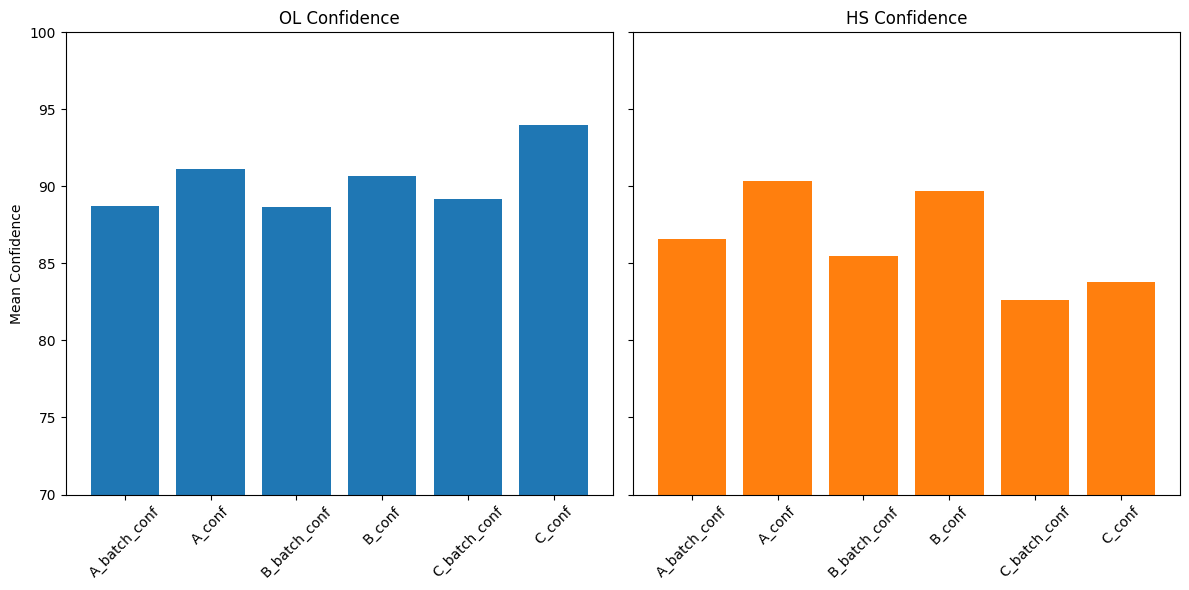

In [20]:
### PLOT
palette = {'OL': '#1f77b4', 'HS': '#ff7f0e'}
# Separate normal and batch conditions
normal_conditions = mean_confidence_wide[mean_confidence_wide['cond_clean'].str.contains("_conf$")]
batch_conditions = mean_confidence_wide[mean_confidence_wide['cond_clean'].str.contains("_batch_conf")]

# Sort conditions alphabetically by label (A, B, C)
normal_conditions = normal_conditions.sort_values(by="cond_clean")
batch_conditions = batch_conditions.sort_values(by="cond_clean")

# Concatenate for desired order: normal first, then batch
ordered_df = pd.concat([normal_conditions, batch_conditions])

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# Barplot for OL
axes[0].bar(ordered_df['cond_clean'], ordered_df['mean_confidence_OL'], 
            color=palette['OL'])
axes[0].set_title('OL Confidence')
axes[0].set_ylabel('Mean Confidence')
axes[0].tick_params(axis='x', rotation=45)

# Barplot for HS
axes[1].bar(ordered_df['cond_clean'], ordered_df['mean_confidence_HS'], 
           color=palette['HS'])
axes[1].set_title('HS Confidence')
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylim(70, 100)  # Set y-axis limit from 60 to 90

plt.tight_layout()
plt.show()
# self reported confidences seem to not be affected at all by the different conditions

<a id="certainty_3"></a>
## Approach 3 to certainty assessment (only non-batch conditions) - LogProb Comparison

i.e., extract the logprobs for the next tokens 
e.g.   
tweet A in condition X: OL-Confidence-Scores: 4, 3, 4 --> Confidenc: = 3.66
tweet 4 in condition X: OL-Confidence-Scores: 4, 4, 4 --> Confidenc: = 4.00combined_df

In [131]:
logprob_conditions = ['A', 'B', 'C.OL', 'C.HS',
                      'A_conf', 'B_conf', 'C.OL_conf', 'C.HS_conf']
pd.set_option('display.max_columns', None)
logprob_df = combined_df[combined_df['condition'].isin(logprob_conditions)].copy()
# logprob_df[logprob_df['tweet_id'] == 1371]

In [133]:
# Get long df with the tokens
ID_VARS = ['batch_id', 'tweet_in_batch', 'tweet_id', 'tweet', 'condition','shot']

# Create a long DataFrame manually by combining all raters
raters = ['R1', 'R2', 'R3']

long_rows = []

for r in raters:
    temp = logprob_df[ID_VARS].copy()
    temp['Rater'] = r
    temp['label'] = logprob_df[f'{r}_label']
    temp['score'] = logprob_df[f'{r}_score']
    temp['Token1'] = logprob_df[f'{r}_Token1']
    temp['Token2'] = logprob_df[f'{r}_Token2']
    temp['Token3'] = logprob_df[f'{r}_Token3']
    temp['Token4'] = logprob_df[f'{r}_Token4']
    temp['Token5'] = logprob_df[f'{r}_Token5']
    long_rows.append(temp)

# Concatenate into a long format DataFrame
long_df = pd.concat(long_rows, ignore_index=True)
long_df.head(6)

,batch_id,tweet_in_batch,tweet_id,tweet,condition,shot,Rater,label,score,Token1,Token2,Token3,Token4,Token5
0,1,1,811,Fat fucking funky nasty ass hoes,A_conf,few-shot,R1,"['OL', 'HS']","['100', '70']",OL 0.000 \n OL -17.500\nAL -19.750\nUL -21.750\nOW -21.875\ndtype: float64,90 -0.743974 \n95 -0.993974 \n100 -1.868974 \n85 -7.993974 \n98 -10.618974\ndtype: float64,", 0.000 \n; -22.875\n , -24.375\n， -25.625\n: -26.500\ndtype: float64",HS -0.038048 \n NH -3.288048 \n NS -12.288048\n NO -13.788048\n H -15.038048\ndtype: float64,90 -0.910731\n80 -1.035731\n0 -1.910731\n70 -3.160731\n50 -4.160730\ndtype: float64
1,1,1,811,Fat fucking funky nasty ass hoes,B_conf,few-shot,R1,"['NH', 'OL']","['90', '95']",HS -0.693151 \nNH -0.693151 \nHH -13.568151\nHN -14.068151\nH -14.818151\ndtype: float64,90 -1.070942\n80 -1.320942\n70 -1.320942\n85 -3.070941\n10 -3.320941\ndtype: float64,", 0.000 \n; -23.750\n , -24.875\n， -25.500\n، -26.000\ndtype: float64",OL 0.000 \nOL -19.750\n -23.750\n O -25.250\n AL -25.375\ndtype: float64,100 -0.479597 \n95 -0.979597 \n90 -5.354597 \n85 -7.229597 \n80 -10.229597\ndtype: float64
2,1,1,811,Fat fucking funky nasty ass hoes,C.OL_conf,few-shot,R1,['OL'],['95'],OL 0.000 \n OL -17.875\nAL -19.750\nUL -21.750\nOLA -21.750\ndtype: float64,95 -0.394199\n100 -1.144199\n90 -5.144199\n98 -7.019199\n99 -7.644199\ndtype: float64,NaN,NaN,NaN
3,1,1,811,Fat fucking funky nasty ass hoes,C.HS_conf,few-shot,R1,['HS'],['90'],HS -0.000002 \nH -13.500002\nNH -14.750002\n HS -16.750002\nHN -18.250002\ndtype: float64,85 -0.45321\n90 -1.07821\n95 -3.95321\n75 -5.32821\n80 -9.70321\ndtype: float64,NaN,NaN,NaN
4,1,1,811,Fat fucking funky nasty ass hoes,A,few-shot,R1,"OL, NH",NaN,OL 0.000 \n OL -16.875\nAL -19.500\nOW -21.250\nUL -21.375\ndtype: float64,", 0.000 \n; -24.125\n , -25.000\n， -25.250\n: -26.000\ndtype: float64",NH -0.000045 \n NO -10.000046\n NS -17.750046\n HS -18.000046\n N -18.750046\ndtype: float64,NaN,NaN
5,1,1,811,Fat fucking funky nasty ass hoes,B,few-shot,R1,"HS, OL",NaN,HS -0.023262 \nNH -3.773262 \nH -11.898262\nHH -12.523262\nHN -12.523262\ndtype: float64,", 0.000 \n , -21.625\n and -24.000\n; -24.125\n: -24.500\ndtype: float64",OL 0.000 \nOL -20.000\n HL -20.250\n O -24.125\n OH -24.500\ndtype: float64,NaN,NaN


In [134]:
# Get the probability of the OL tokens 
# for condition A and A_conf this is token 1
# for condition B, this is token 3
# for condition B_conf, this is token 4
# for condition C.OL this is token 1 
conditions_OL = [
    long_df['condition'] == 'A',
    long_df['condition'] == 'A_conf',
    long_df['condition'] == 'B',
    long_df['condition'] == 'B_conf',
    long_df['condition'] == 'C.OL',
    long_df['condition'] == 'C.OL_conf'
    # long_df['condition'] == 'C.HS',
    # long_df['condition'] == 'C.HS_conf'
]

choices_OL = [
    long_df['Token1'],
    long_df['Token1'],
    long_df['Token3'],
    long_df['Token4'],
    long_df['Token1'],
    long_df['Token1']
    # long_df['Token1'], # not applicable
    # long_df['Token1']  #
]

long_df['OL_top5_logprobs'] = np.select(conditions_OL, choices_OL, default= np.nan)
long_df

# Same for HS tokens
conditions_HS = [
    long_df['condition'] == 'A',
    long_df['condition'] == 'A_conf',
    long_df['condition'] == 'B',
    long_df['condition'] == 'B_conf',
    # long_df['condition'] == 'C.OL',
    # long_df['condition'] == 'C.OL_conf',
    long_df['condition'] == 'C.HS',
    long_df['condition'] == 'C.HS_conf'
]

choices_HS = [
    long_df['Token3'],
    long_df['Token4'],
    long_df['Token1'],
    long_df['Token1'],
    # long_df['Token1'], # not applicable
    # long_df['Token1'], # 
    long_df['Token1'],
    long_df['Token1']
]

long_df['HS_top5_logprobs'] = np.select(conditions_HS, choices_HS, default= np.nan)
pd.set_option('display.max_colwidth', None)
# long_df

In [23]:
import re, math, pandas as pd

# matches:  <any text> <spaces> <number>   (number = int/float/scientific)
LOGPAT = re.compile(
    r'^(?P<tok>.*?)\s+(?P<logp>[-+]?(?:\d*\.\d+|\d+)(?:e[-+]?\d+)?)\s*$',
    flags=re.I
)

def to_list(cell) -> list[tuple[str, float]]:
    """
    Turn one OL_top5_logprobs cell into an *ordered* list of (token, logprob).
    • Keeps leading/trailing blanks inside the token, allows the token to be ''.
    • Silently returns [] on NaN / non-string inputs.
    """
    if not isinstance(cell, str):
        return []

    out = []
    for line in cell.split('\n'):
        m = LOGPAT.match(line)
        if m:
            tok   = m.group('tok')            # e.g. ' OL', '' (empty), etc.
            out.append((tok, float(m.group('logp'))))
    return out

# 2️⃣  Apply to every row …
long_df["OL_top5_list"] = long_df["OL_top5_logprobs"].apply(to_list)
long_df["HS_top5_list"] = long_df["HS_top5_logprobs"].apply(to_list)

print(f'Sample first row logprobs: {long_df.loc[0, "OL_top5_list"]}')
# long_df.head()

Sample first row logprobs: [('OL', 0.0), (' OL', -17.5), ('AL', -19.75), ('UL', -21.75), ('OW', -21.875)]


In [21]:
# Get the logprobs for the relevant token
long_df['OL_first_token_logprob'] = (
    long_df['OL_top5_list']
        .apply(lambda lst: lst[0][1] if lst and len(lst[0]) == 2 else np.nan)
)

long_df['HS_first_token_logprob'] = (
    long_df['HS_top5_list']
        .apply(lambda lst: lst[0][1] if lst and len(lst[0]) == 2 else np.nan)
)


# Get the Probabilities for the relevant token
long_df['OL_first_token_prob'] = (
    long_df['OL_top5_list']
      .apply(lambda lst: np.exp(lst[0][1]) if lst and len(lst[0]) == 2 else np.nan)
)

long_df['HS_first_token_prob'] = (
    long_df['HS_top5_list']
      .apply(lambda lst: np.exp(lst[0][1]) if lst and len(lst[0]) == 2 else np.nan)
)

pd.set_option('display.float_format', '{:.10f}'.format)
long_df[['tweet_id', 'tweet', 'condition', 
         'OL_top5_list', 'HS_top5_list', 
         'OL_first_token_logprob', 'HS_first_token_logprob', 
         'OL_first_token_prob', 'HS_first_token_prob']].head(2)

,tweet_id,tweet,condition,OL_top5_list,HS_top5_list,OL_first_token_logprob,HS_first_token_logprob,OL_first_token_prob,HS_first_token_prob
0,811,Fat fucking funky nasty ass hoes,A_conf,"[(OL, 0.0), ( OL, -17.5), (AL, -19.75), (UL, -21.75), (OW, -21.875)]","[( HS, -0.038048), ( NH, -3.288048), ( NS, -12.288048), ( NO, -13.788048), ( H, -15.038048)]",0.0000000000,-0.0380480000,1.0000000000,0.9626667318
1,811,Fat fucking funky nasty ass hoes,B_conf,"[( OL, 0.0), (OL, -19.75), (, -23.75), ( O, -25.25), ( AL, -25.375)]","[(HS, -0.693151), (NH, -0.693151), (HH, -13.568151), (HN, -14.068151), (H, -14.818151)]",0.0000000000,-0.6931510000,1.0000000000,0.4999980903


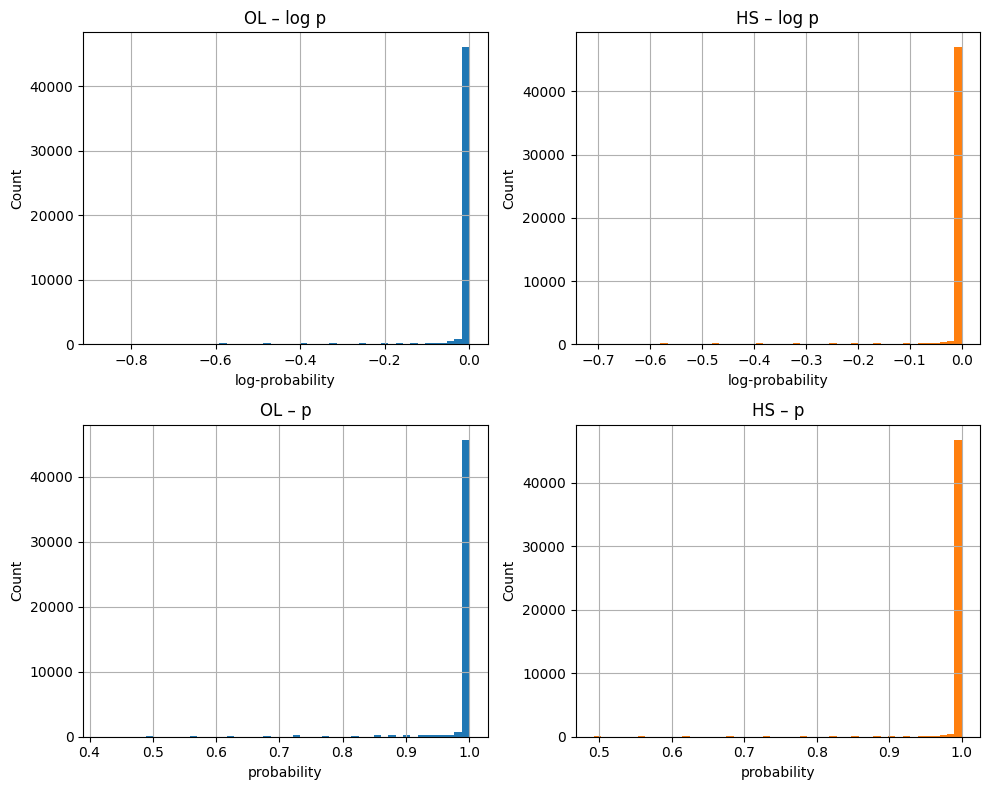

In [22]:
# Plot
palette = {'OL': '#1f77b4', 'HS': '#ff7f0e'}

ig, axes = plt.subplots(2, 2, figsize=(10, 8))

# ── Row 1 : log-probs ───────────────────────────────────────────
long_df['OL_first_token_logprob'].hist(bins=50,
                                       color=palette['OL'],
                                       ax=axes[0, 0])
axes[0, 0].set_title('OL – log p')
axes[0, 0].set_xlabel('log-probability')
axes[0, 0].set_ylabel('Count')

long_df['HS_first_token_logprob'].hist(bins=50,
                                       color=palette['HS'],
                                       ax=axes[0, 1])
axes[0, 1].set_title('HS – log p')
axes[0, 1].set_xlabel('log-probability')
axes[0, 1].set_ylabel('Count')

# ── Row 2 : plain probabilities ────────────────────────────────
long_df['OL_first_token_prob'].hist(bins=50,
                                    color=palette['OL'],
                                    ax=axes[1, 0])
axes[1, 0].set_title('OL – p')
axes[1, 0].set_xlabel('probability')
axes[1, 0].set_ylabel('Count')

long_df['HS_first_token_prob'].hist(bins=50,
                                    color=palette['HS'],
                                    ax=axes[1, 1])
axes[1, 1].set_title('HS – p')
axes[1, 1].set_xlabel('probability')
axes[1, 1].set_ylabel('Count')

plt.tight_layout()
plt.show()

## Calculate the Top K Disparty Scores (as described in the XYZ Paper)

In [103]:
# Get the logprobs for the relevant token
long_df['OL_first_token_logprob'] = (
    long_df['OL_top5_list']
        .apply(lambda lst: lst[0][1] if lst and len(lst[0]) == 2 else np.nan)
)

long_df['HS_first_token_logprob'] = (
    long_df['HS_top5_list']
        .apply(lambda lst: lst[0][1] if lst and len(lst[0]) == 2 else np.nan)
)


long_df['OL_second_token_logprob'] = (
    long_df['OL_top5_list']
        .apply(lambda lst: lst[1][1] if lst and len(lst[0]) == 2 else np.nan)
)

long_df['HS_second_token_logprob'] = (
    long_df['HS_top5_list']
        .apply(lambda lst: lst[1][1] if lst and len(lst[0]) == 2 else np.nan)
)


# Get the Probabilities for the relevant token
long_df['OL_first_token_prob'] = (
    long_df['OL_top5_list']
      .apply(lambda lst: np.exp(lst[0][1]) if lst and len(lst[0]) == 2 else np.nan)
)

long_df['HS_first_token_prob'] = (
    long_df['HS_top5_list']
      .apply(lambda lst: np.exp(lst[0][1]) if lst and len(lst[0]) == 2 else np.nan)
)


long_df['OL_second_token_prob'] = (
    long_df['OL_top5_list']
      .apply(lambda lst: np.exp(lst[1][1]) if lst and len(lst[0]) == 2 else np.nan)
)

long_df['HS_second_token_prob'] = (
    long_df['HS_top5_list']
      .apply(lambda lst: np.exp(lst[1][1]) if lst and len(lst[0]) == 2 else np.nan)
)

pd.set_option('display.float_format', '{:.10f}'.format)
long_df[['tweet_id', 'tweet', 'condition', 
         'OL_top5_list', 'HS_top5_list', 
         'OL_first_token_logprob', 'HS_first_token_logprob', 
         'OL_second_token_logprob', 'HS_second_token_logprob',
         'OL_first_token_prob', 'HS_first_token_prob',
         'OL_second_token_prob', 'HS_second_token_prob']].head(2)



,tweet_id,tweet,condition,OL_top5_list,HS_top5_list,OL_first_token_logprob,HS_first_token_logprob,OL_second_token_logprob,HS_second_token_logprob,OL_first_token_prob,HS_first_token_prob,OL_second_token_prob,HS_second_token_prob
0,811,Fat fucking funky nasty ass hoes,A_conf,"[(OL, 0.0), ( OL, -17.5), (AL, -19.75), (UL, -21.75), (OW, -21.875)]","[( HS, -0.038048), ( NH, -3.288048), ( NS, -12.288048), ( NO, -13.788048), ( H, -15.038048)]",0.0000000000,-0.0380480000,-17.5000000000,-3.2880480000,1.0000000000,0.9626667318,0.0000000251,0.0373266399
1,811,Fat fucking funky nasty ass hoes,B_conf,"[( OL, 0.0), (OL, -19.75), (, -23.75), ( O, -25.25), ( AL, -25.375)]","[(HS, -0.693151), (NH, -0.693151), (HH, -13.568151), (HN, -14.068151), (H, -14.818151)]",0.0000000000,-0.6931510000,-19.7500000000,-0.6931510000,1.0000000000,0.4999980903,0.0000000026,0.4999980903


In [104]:
# We have to split this for the different conditions A,B,C and for base vs. conf condition
# --> larger values --> larger certainty
long_df['top2_token_disparity_OL'] = long_df['OL_first_token_logprob'] - long_df['OL_second_token_logprob']
long_df['top2_token_disparity_HS'] = long_df['HS_first_token_logprob'] - long_df['HS_second_token_logprob']
long_df.head(3)

,batch_id,tweet_in_batch,tweet_id,tweet,condition,shot,Rater,label,score,Token1,Token2,Token3,Token4,Token5,OL_top5_logprobs,HS_top5_logprobs,OL_top5_list,HS_top5_list,OL_first_token_logprob,HS_first_token_logprob,OL_first_token_prob,HS_first_token_prob,OL_second_token_logprob,HS_second_token_logprob,OL_second_token_prob,HS_second_token_prob,top2_token_dispartiy_OL,top2_token_dispartiy_HS,top2_token_disparity_OL,top2_token_disparity_HS
0,1,1,811,Fat fucking funky nasty ass hoes,A_conf,few-shot,R1,"['OL', 'HS']","['100', '70']",OL 0.000 \n OL -17.500\nAL -19.750\nUL -21.750\nOW -21.875\ndtype: float64,90 -0.743974 \n95 -0.993974 \n100 -1.868974 \n85 -7.993974 \n98 -10.618974\ndtype: float64,", 0.000 \n; -22.875\n , -24.375\n， -25.625\n: -26.500\ndtype: float64",HS -0.038048 \n NH -3.288048 \n NS -12.288048\n NO -13.788048\n H -15.038048\ndtype: float64,90 -0.910731\n80 -1.035731\n0 -1.910731\n70 -3.160731\n50 -4.160730\ndtype: float64,OL 0.000 \n OL -17.500\nAL -19.750\nUL -21.750\nOW -21.875\ndtype: float64,HS -0.038048 \n NH -3.288048 \n NS -12.288048\n NO -13.788048\n H -15.038048\ndtype: float64,"[(OL, 0.0), ( OL, -17.5), (AL, -19.75), (UL, -21.75), (OW, -21.875)]","[( HS, -0.038048), ( NH, -3.288048), ( NS, -12.288048), ( NO, -13.788048), ( H, -15.038048)]",0.0000000000,-0.0380480000,1.0000000000,0.9626667318,-17.5000000000,-3.2880480000,0.0000000251,0.0373266399,17.5000000000,3.2500000000,17.5000000000,3.2500000000
1,1,1,811,Fat fucking funky nasty ass hoes,B_conf,few-shot,R1,"['NH', 'OL']","['90', '95']",HS -0.693151 \nNH -0.693151 \nHH -13.568151\nHN -14.068151\nH -14.818151\ndtype: float64,90 -1.070942\n80 -1.320942\n70 -1.320942\n85 -3.070941\n10 -3.320941\ndtype: float64,", 0.000 \n; -23.750\n , -24.875\n， -25.500\n، -26.000\ndtype: float64",OL 0.000 \nOL -19.750\n -23.750\n O -25.250\n AL -25.375\ndtype: float64,100 -0.479597 \n95 -0.979597 \n90 -5.354597 \n85 -7.229597 \n80 -10.229597\ndtype: float64,OL 0.000 \nOL -19.750\n -23.750\n O -25.250\n AL -25.375\ndtype: float64,HS -0.693151 \nNH -0.693151 \nHH -13.568151\nHN -14.068151\nH -14.818151\ndtype: float64,"[( OL, 0.0), (OL, -19.75), (, -23.75), ( O, -25.25), ( AL, -25.375)]","[(HS, -0.693151), (NH, -0.693151), (HH, -13.568151), (HN, -14.068151), (H, -14.818151)]",0.0000000000,-0.6931510000,1.0000000000,0.4999980903,-19.7500000000,-0.6931510000,0.0000000026,0.4999980903,19.7500000000,0.0000000000,19.7500000000,0.0000000000
2,1,1,811,Fat fucking funky nasty ass hoes,C.OL_conf,few-shot,R1,['OL'],['95'],OL 0.000 \n OL -17.875\nAL -19.750\nUL -21.750\nOLA -21.750\ndtype: float64,95 -0.394199\n100 -1.144199\n90 -5.144199\n98 -7.019199\n99 -7.644199\ndtype: float64,NaN,NaN,NaN,OL 0.000 \n OL -17.875\nAL -19.750\nUL -21.750\nOLA -21.750\ndtype: float64,NaN,"[(OL, 0.0), ( OL, -17.875), (AL, -19.75), (UL, -21.75), (OLA, -21.75)]",[],0.0000000000,NaN,1.0000000000,NaN,-17.8750000000,NaN,0.0000000173,NaN,17.8750000000,NaN,17.8750000000,NaN


In [114]:
# Merge the C Conditions
# Create DF for confidencs score investigation 
# --> i.e., merge the C.OL and C.HS conditions to one condition
# base df
disparity_df = long_df[[
    'batch_id', 'tweet_in_batch', 'tweet_id',  'tweet', 
    'condition', 'Rater',
    'shot', 
    'label','OL_top5_list','HS_top5_list',
    'top2_token_disparity_OL','top2_token_disparity_HS'
    ]].copy()

key_cols = ["batch_id", "tweet_in_batch", "tweet_id", 
            "tweet", "condition", "shot",'Rater',
            "cond_clean"]

disparity_df['cond_clean'] = disparity_df['condition'].str.replace(r'\.OL|\.HS', '', regex=True)




confidence_df_A_B = disparity_df[disparity_df['condition'].str.contains(r'[AB]', na=False)].copy()

# C conditions --> sepcial: join binary OL ratings from C.OL base df 
#                           same for binary HS ratings
disparity_df_C = disparity_df[key_cols].copy().drop_duplicates(subset=['tweet_id', 'cond_clean','Rater'])

# join binary OL ratings
disparity_df_C = disparity_df_C.merge(disparity_df[disparity_df['condition'].str.contains(r'C\.OL', na=False)]
                                  [['tweet', 'cond_clean', 'Rater',
                                   'OL_top5_list',
                                    'top2_token_disparity_OL']], 
                   left_on=['tweet', 'cond_clean', 'Rater'], 
                   right_on=['tweet', 'cond_clean', 'Rater'])
# join binary HS ratings
disparity_df_C = disparity_df_C.merge(disparity_df[disparity_df['condition'].str.contains(r'C\.HS', na=False)]
                                  [['tweet', 'cond_clean', 'Rater',
                                   'HS_top5_list',
                                    'top2_token_disparity_HS']], 
                   left_on=['tweet', 'cond_clean', 'Rater'], 
                   right_on=['tweet', 'cond_clean', 'Rater'])

disparity_df_C[disparity_df_C['tweet_id'] == 811].head()


# # Concat to get the final reformatted df for calculating entropies
disparity_df = pd.concat([confidence_df_A_B, disparity_df_C], 
                       ignore_index=True, sort=False)
# disparity_df[(disparity_df['tweet_id'] == 811) & 
#              (disparity_df['cond_clean'].str.contains('C'))].head(20)



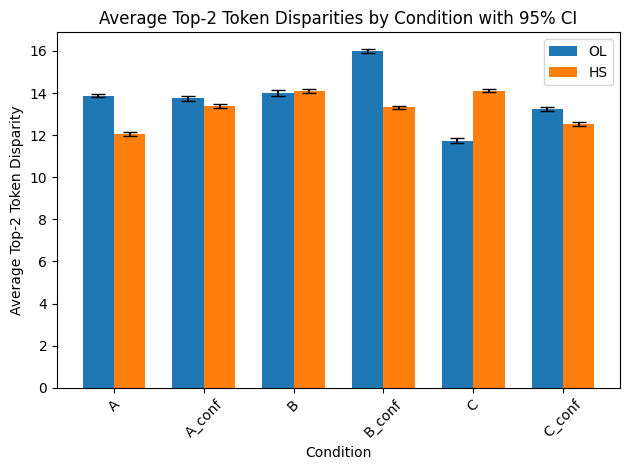

In [115]:
# 1) pull out means and SEMs
stats = (disparity_df
  .groupby('cond_clean')[['top2_token_disparity_OL','top2_token_disparity_HS']]
  .agg(['mean','sem'])
)

# flatten the multi-index columns
stats.columns = ['_'.join(col) for col in stats.columns]


means = stats[['top2_token_disparity_OL_mean', 'top2_token_disparity_HS_mean']]
sems  = stats[['top2_token_disparity_OL_sem',  'top2_token_disparity_HS_sem']]

# then 95% CI
ci95 = 1.96 * sems

# now means and ci95 are real DataFrames with named columns:
# you can safely do:
# Bars
plt.bar(index, means['top2_token_disparity_OL_mean'], 
        yerr=ci95['top2_token_disparity_OL_sem'],
        width=bar_width, label='OL', capsize=5)
plt.bar(index + bar_width, means['top2_token_disparity_HS_mean'], 
        yerr=ci95['top2_token_disparity_HS_sem'],
        width=bar_width, label='HS', capsize=5)

# Labels and formatting
plt.xlabel('Condition')
plt.ylabel('Average Top-2 Token Disparity')
plt.title('Average Top-2 Token Disparities by Condition with 95% CI')
plt.xticks(index + bar_width / 2, conditions, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [145]:
# CORRELATIONS BETWEEN THE DIFFERENT LABEL CERTAINTY ASSESSMENTS

entropy_df.head() # tweet level
confidence_df.head() # rater level, rowwise
disparity_df.head() # rater level long-format 

# Reformat s.t. we get one confidence value per tweet x condition
confidence_df['mean_confidence_OL'] = confidence_df[
    ['R1_OL_confidence',
     'R2_OL_confidence',
     'R3_OL_confidence']].mean(axis=1)
confidence_df['mean_confidence_HS'] = confidence_df[
    ['R1_HS_confidence',
     'R2_HS_confidence',
     'R3_HS_confidence']].mean(axis=1)

# Reformat disparity df s.t. we get one disparity value per tweet
# i.e., the tweet level mean of disparities across raters

# assuming `df` is your long‐form DataFrame
disparity_df_means = (
    disparity_df
    .groupby(['cond_clean', 'tweet_id'])[
        ['top2_token_disparity_OL', 'top2_token_disparity_HS']
    ]
    .mean()
    .rename(columns={
        'top2_token_disparity_OL': 'mean_disparity_OL',
        'top2_token_disparity_HS': 'mean_disparity_HS'
    })
    .reset_index()
)
# disparity_df_means

In [146]:
entropy_df

,batch_id,tweet_in_batch,tweet_id,tweet,condition,shot,R1_label,R2_label,R3_label,cond_clean,R1_OL,R2_OL,R3_OL,R1_HS,R2_HS,R3_HS,entropy_OL,entropy_HS
0,1,1,811,Fat fucking funky nasty ass hoes,A_conf,few-shot,"['OL', 'HS']","['OL', 'NH']","['OL', 'NH']",A_conf,1,1,1,1,0,0,-0.0000000000,0.9182958341
1,1,1,811,Fat fucking funky nasty ass hoes,B_conf,few-shot,"['NH', 'OL']","['NH', 'OL']","['NH', 'OL']",B_conf,1,1,1,0,0,0,-0.0000000000,-0.0000000000
2,1,1,811,Fat fucking funky nasty ass hoes,A,few-shot,"OL, NH","OL, NH","OL, NH",A,1,1,1,0,0,0,-0.0000000000,-0.0000000000
3,1,1,811,Fat fucking funky nasty ass hoes,B,few-shot,"HS, OL","HS, OL","HS, OL",B,1,1,1,1,1,1,-0.0000000000,-0.0000000000
4,1,1,811,Fat fucking funky nasty ass hoes,A_batch_conf,few-shot,"['OL', 'NH']","['OL', 'NH']","['OL', 'NH']",A_batch_conf,1,1,1,0,0,0,-0.0000000000,-0.0000000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34623,500,5,1906,@###### better off banning teabaggers and their anti American supporters,C.HS_batch_conf,few-shot,['HS'],['HS'],['HS'],C_batch_conf,1,1,1,1,1,1,-0.0000000000,-0.0000000000
34624,500,5,1906,@###### better off banning teabaggers and their anti American supporters,C.HS_batch,few-shot,['HS'],['HS'],['HS'],C_batch,1,1,1,1,1,1,-0.0000000000,-0.0000000000
34625,500,6,433,hell would freeze over before I ever let any bitch kick me in the fuckin face,C.HS,few-shot,NH,NH,NH,C,1,1,1,0,0,0,-0.0000000000,-0.0000000000
34626,500,6,433,hell would freeze over before I ever let any bitch kick me in the fuckin face,C.HS_batch_conf,few-shot,['NH'],['NH'],['NH'],C_batch_conf,1,1,1,0,0,0,-0.0000000000,-0.0000000000


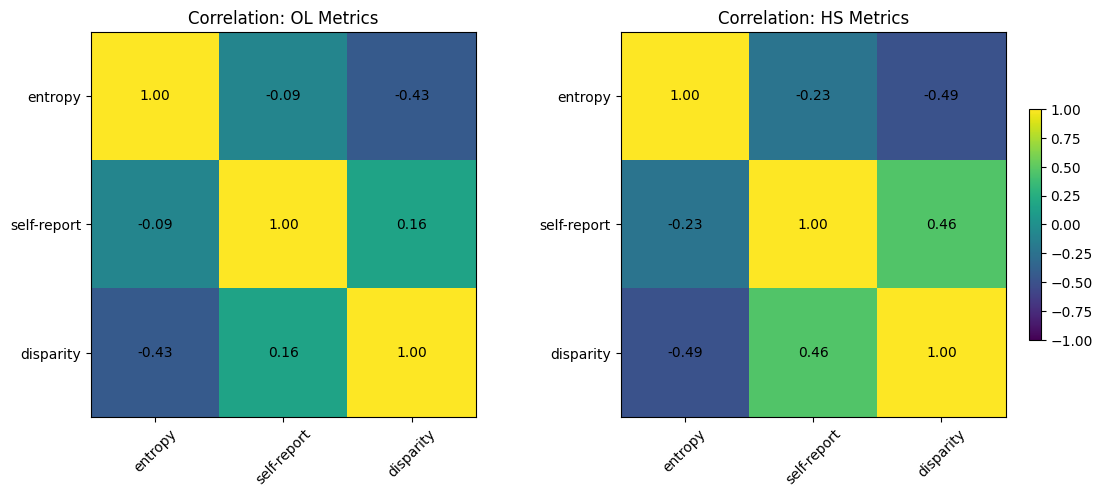

In [164]:
# get Correlations 
import pandas as pd
import matplotlib.pyplot as plt


# ———————————————
# 1) Prepare the OL merged df and correlation
merged_ol = (
    entropy_df[['tweet_id', 'cond_clean', 'entropy_OL']].rename(columns={'entropy_OL': 'entropy'})
    .merge(
        confidence_df[['tweet_id', 'cond_clean', 'mean_confidence_OL']].rename(columns={'mean_confidence_OL': 'self-report'}),
        on=['tweet_id', 'cond_clean']
    )
    .merge(
        disparity_df_means[['tweet_id', 'cond_clean', 'mean_disparity_OL']].rename(columns={'mean_disparity_OL': 'disparity'}),
        on=['tweet_id', 'cond_clean']
    )
)
corr_ol = merged_ol[['entropy', 'self-report', 'disparity']].corr()

# ———————————————
# 2) Prepare the HS merged df and correlation
merged_hs = (
    entropy_df[['tweet_id', 'cond_clean', 'entropy_HS']].rename(columns={'entropy_HS': 'entropy'})
    .merge(
        confidence_df[['tweet_id', 'cond_clean', 'mean_confidence_HS']].rename(columns={'mean_confidence_HS': 'self-report'}),
        on=['tweet_id', 'cond_clean']
    )
    .merge(
        disparity_df_means[['tweet_id', 'cond_clean', 'mean_disparity_HS']].rename(columns={'mean_disparity_HS': 'disparity'}),
        on=['tweet_id', 'cond_clean']
    )
)
corr_hs = merged_hs[['entropy', 'self-report', 'disparity']].corr()

# ———————————————
# 3) Plot both heatmaps side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# OL heatmap
im0 = axes[0].imshow(corr_ol, aspect='equal', vmin=-1, vmax=1)
axes[0].set_xticks(range(len(corr_ol)))
axes[0].set_xticklabels(corr_ol.columns, rotation=45)
axes[0].set_yticks(range(len(corr_ol)))
axes[0].set_yticklabels(corr_ol.index)
axes[0].set_title('Correlation: OL Metrics')

# annotate OL
for i in range(corr_ol.shape[0]):
    for j in range(corr_ol.shape[1]):
        axes[0].text(
            j, i,
            f"{corr_ol.iloc[i, j]:.2f}",
            ha='center', va='center',
            color='black' if abs(corr_ol.iloc[i, j]) > 0.5 else 'black'
        )

# HS heatmap
im1 = axes[1].imshow(corr_hs, aspect='equal', vmin=-1, vmax=1)
axes[1].set_xticks(range(len(corr_hs)))
axes[1].set_xticklabels(corr_hs.columns, rotation=45)
axes[1].set_yticks(range(len(corr_hs)))
axes[1].set_yticklabels(corr_hs.index)
axes[1].set_title('Correlation: HS Metrics')

# annotate HS
for i in range(corr_hs.shape[0]):
    for j in range(corr_hs.shape[1]):
        axes[1].text(
            j, i,
            f"{corr_hs.iloc[i, j]:.2f}",
            ha='center', va='center',
            color='black' if abs(corr_hs.iloc[i, j]) > 0.5 else 'black'
        )

# make room and draw colorbar
fig.subplots_adjust(right=1.1)
fig.colorbar(im1, ax=axes.ravel().tolist(), shrink=0.6, pad=0.02)

plt.show()